## 5. MCP

### 5.1 Connecting an app by hand: Notion

So far our tools were small functions. Let's connect a real app: **Notion**. Gemini will add tasks to your Notion to-do list, read them and delete them.

To do this, we write one function for every action, using Notion's API.

#### Set up Notion (2 minutes, free plan works)

1. Open https://www.notion.so/developers/tokens and click **New token**. Give it a name, select **Notion API**, create it and copy the token.
2. In Notion, create a new empty page called **My To-Do List**.
3. Copy the page link. The **page ID** is the long code (32 letters and numbers) at the end of the link.

   Example link: `https://app.notion.com/p/Learning-Notion-YOUR_PAGE_ID`

   Page ID: `YOUR_PAGE_ID`

# Paste your Notion token and page ID (DON'T SHARE THE TOKEN WITH ANYONE!)

NOTION_TOKEN = userdata.get("NOTION_TOKEN")   # saved in Colab Secrets, never in the code
NOTION_PAGE_ID = "PASTE_YOUR_PAGE_ID_HERE"

In [16]:
# STEP 0 (run once): install the SDKs
# WHY (tech): Installs each provider's Python SDK, which handles HTTP requests, authentication and response parsing.
# ELI5: Download a translator app for each AI company.
!pip install -q -U google-genai openai anthropic
# If you later get an ImportError: Runtime -> Restart session, then run the cells again (skip this one).

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.


In [17]:
from google import genai
from google.genai import types
from google.colab import userdata
gemini = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODEL = "gemini-3.8-flash"
test = gemini.models.generate_content(model=MODEL, contents="Say OK")
print("✅ Gemini connected:", test.text)

from openai import OpenAI
from google.colab import userdata
openai_client = OpenAI(api_key=userdata.get("OPENAI_API_KEY"))
MODEL = "gpt-6.1-sol"
test = openai_client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
print("✅ OpenAI connected:", test.choices[0].message.content)

import anthropic
from google.colab import userdata
claude = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
MODEL = "claude-sonnet-5-5"
test = claude.messages.create(model=MODEL, max_tokens=20, messages=[{"role": "user", "content": "Say OK"}])
print("✅ Claude connected:", test.content[-1].text)

from openai import OpenAI
from google.colab import userdata
groq = OpenAI(api_key=userdata.get("GROQ_API_KEY"), base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"
test = groq.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say OK"}])
print("✅ Groq connected:", test.choices[0].message.content)

✅ Gemini connected: OK
✅ OpenAI connected: OK
✅ Claude connected: OK
✅ Groq connected: OK


In [1]:
# Paste your Notion token and page ID (DON'T SHARE THE TOKEN WITH ANYONE!)

NOTION_TOKEN = userdata.get("NOTION_TOKEN")   # saved in Colab Secrets, never in the code
NOTION_PAGE_ID = "PASTE_YOUR_PAGE_ID_HERE"

In [18]:
!pip install -q notion-client ##important

from notion_client import Client

notion = Client(auth=NOTION_TOKEN)

In [20]:
def add_tasks(tasks: list[str]) -> str:
    """Add one or more tasks to my Notion to-do list."""
    print("Tool called! Adding tasks:", tasks)

    new_tasks = []
    for task in tasks:
        new_tasks.append({
            "object": "block",
            "type": "to_do",
            "to_do": {"rich_text": [{"type": "text", "text": {"content": task}}]},
        })

    notion.blocks.children.append(block_id=NOTION_PAGE_ID, children=new_tasks)
    return f"Added {len(tasks)} tasks"


def get_tasks() -> str:
    """Get all tasks from my Notion to-do list, with their status."""
    print("Tool called! Reading tasks from Notion")
    blocks = notion.blocks.children.list(block_id=NOTION_PAGE_ID)["results"]

    tasks = []
    for block in blocks:
        if block["type"] == "to_do" and block["to_do"]["rich_text"]:
            name = block["to_do"]["rich_text"][0]["plain_text"]
            status = "done" if block["to_do"]["checked"] else "pending"
            tasks.append(f"{name} ({status})")

    return "\n".join(tasks) if tasks else "No tasks yet"


def find_task(task_name):
    """Find a task on the Notion page and return its ID."""
    blocks = notion.blocks.children.list(block_id=NOTION_PAGE_ID)["results"]

    for block in blocks:
        if block["type"] == "to_do" and block["to_do"]["rich_text"]:
            name = block["to_do"]["rich_text"][0]["plain_text"]
            if task_name.lower() in name.lower():
                return block["id"]
    return None


def edit_task(old_task: str, new_task: str) -> str:
    """Rename a task in my Notion to-do list. old_task can be part of the task name."""
    print("Tool called! Editing task:", old_task, "->", new_task)
    task_id = find_task(old_task)
    if task_id is None:
        return f"Task not found: {old_task}"

    notion.blocks.update(block_id=task_id, to_do={"rich_text": [{"type": "text", "text": {"content": new_task}}]})
    return f"Updated to: {new_task}"


def delete_task(task: str) -> str:
    """Delete a task from my Notion to-do list. task can be part of the task name."""
    print("Tool called! Deleting task:", task)
    task_id = find_task(task)
    if task_id is None:
        return f"Task not found: {task}"

    notion.blocks.delete(block_id=task_id)
    return f"Deleted: {task}"

Same as before: a system prompt for the role, and our functions as tools.

In [22]:
#System prompe

notion_config = types.GenerateContentConfig(
    system_instruction="You are my productivity assistant. You manage my to-do list in Notion. Keep answers short.",
    tools=[add_tasks, get_tasks, edit_task, delete_task],
)

In [24]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="I have a FDE exam on Monday. Add 4 study tasks to my to-do list, including one mock test.",
    config=notion_config,
)

print(response.text)

Tool called! Adding tasks: ['Review FDE lecture notes and key concepts', 'Practice FDE problem sets and assignments', 'Complete FDE mock test', 'Review mock test mistakes and weak areas']
Added the following 4 tasks to your to-do list:
1. Review FDE lecture notes and key concepts
2. Practice FDE problem sets and assignments
3. Complete FDE mock test
4. Review mock test mistakes and weak areas


Open your Notion page: the tasks are there! Gemini wrote them and sent them to Notion with `add_tasks`.

In [25]:
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents="Delete the mock test task, and show me what's left on my list.",
    config=notion_config,
)

print(response.text)

Tool called! Deleting task: mock test
Tool called! Reading tasks from Notion
Deleted "mock test". Here is your updated to-do list:

- **Review FDE lecture notes and key concepts** (pending)
- **Practice FDE problem sets and assignments** (pending)
- **Review mock test mistakes and weak areas** (pending)


It works. But look at what it took: **4 functions and ~60 lines** to manage one to-do list.

Now imagine Gmail, Slack, GitHub, Google Drive... Every team writing (and maintaining) the same tools again and again. That's the problem **MCP** solves.

### 5.2 What is MCP?

**MCP (Model Context Protocol)** is a standard way for apps to share their tools with any AI.

- The app builds its tools **once**, as an **MCP server**.
- Your AI connects to it as an **MCP client**, and gets all the tools, ready to use.

Think of it as a **USB-C port for AI**: if an app has an MCP server, any AI can plug into it.

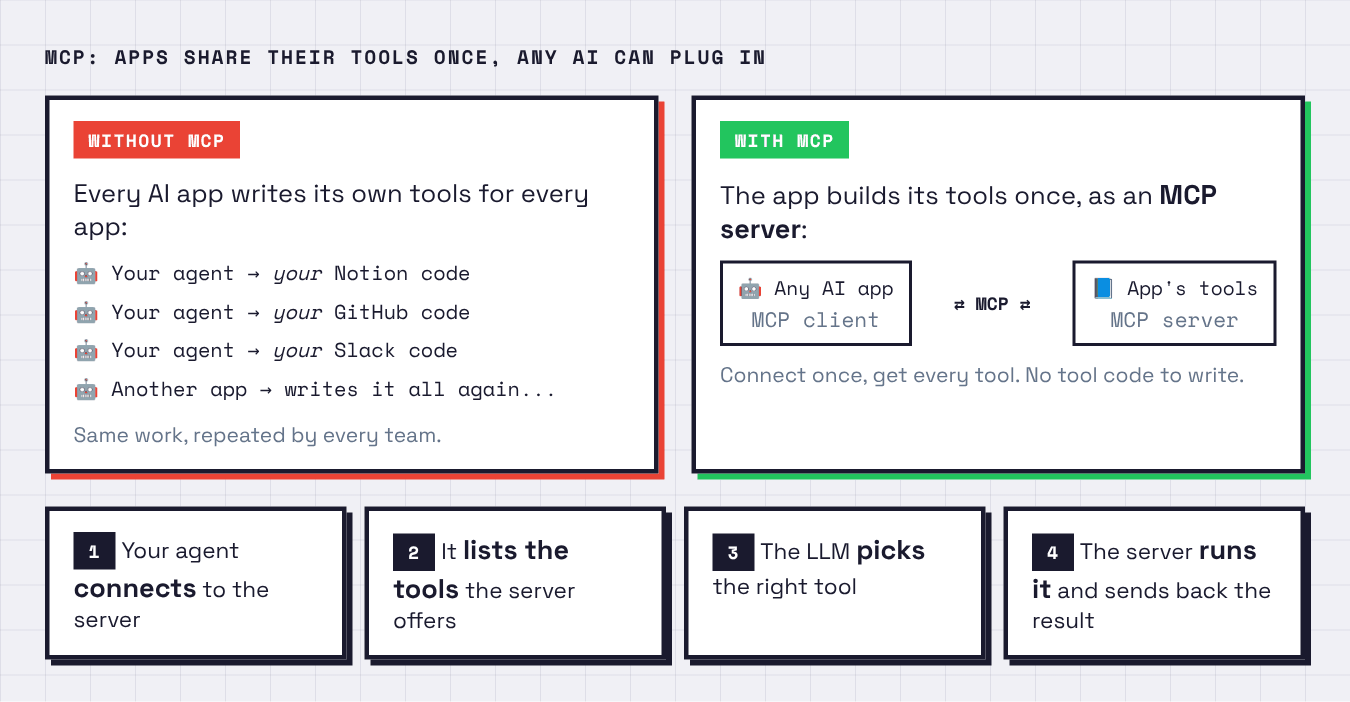

**Note:** Notion also has an official MCP server. In a real project, you'd plug that in instead of writing the functions above.

Open AI to Notion

In [35]:
import json

openai_tools = [
    {"type": "function", "function": {
        "name": "add_tasks",
        "description": "Add one or more tasks to my Notion to-do list. Put EACH task as a separate string.",
        "parameters": {"type": "object",
                       "properties": {"tasks": {"type": "array", "items": {"type": "string"}}},
                       "required": ["tasks"]}}},
    {"type": "function", "function": {
        "name": "get_tasks",
        "description": "Get all tasks from my Notion to-do list, with their status (done/pending).",
        "parameters": {"type": "object", "properties": {}}}},
    {"type": "function", "function": {
        "name": "edit_task",
        "description": "Rename a task. old_task can be part of the current task name.",
        "parameters": {"type": "object",
                       "properties": {"old_task": {"type": "string"}, "new_task": {"type": "string"}},
                       "required": ["old_task", "new_task"]}}},
    {"type": "function", "function": {
        "name": "delete_task",
        "description": "Delete a task. task can be part of the task name. Only use when the user clearly asks to delete.",
        "parameters": {"type": "object",
                       "properties": {"task": {"type": "string"}},
                       "required": ["task"]}}},
]

# Phone book: the tool name GPT uses → your real Python function
TOOLS = {"add_tasks": add_tasks, "get_tasks": get_tasks,
         "edit_task": edit_task, "delete_task": delete_task}

In [37]:
MODEL = "gpt-4o-mini"   # if it gives a 404, use a current model, e.g. "gpt-6.1-sol"

SYSTEM = ("You are my fitness coach. You manage my to-do list in Notion. Keep answers short. "
          "Put each new task as a separate item. Only delete a task when I clearly ask.")

def ask_coach(prompt):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}]

    for step in range(5):                                   # max 5 rounds, so it can't loop forever
        response = openai_client.chat.completions.create(model=MODEL, messages=messages, tools=openai_tools)
        msg = response.choices[0].message
        messages.append(msg)

        if not msg.tool_calls:                              # no more tools requested → final answer
            return msg.content

        for call in msg.tool_calls:                         # run every tool GPT asked for
            args = json.loads(call.function.arguments)      # arguments arrive as text → dict
            result = TOOLS[call.function.name](**args)      # call your real function
            messages.append({"role": "tool", "tool_call_id": call.id, "content": str(result)})

    return "Stopped after 5 steps."

In [38]:
print(ask_coach("Add 2 fitness tasks for today."))

Tool called! Adding tasks: ['30-minute cardio workout', 'Strength training session focusing on upper body']
I've added the following fitness tasks for today:

1. 30-minute cardio workout
2. Strength training session focusing on upper body


In [39]:
print(ask_coach("What's on my list?"))

Tool called! Reading tasks from Notion
Here are your current tasks:

1. Review FDE lecture notes and key concepts (pending)
2. Practice FDE problem sets and assignments (pending)
3. Review mock test mistakes and weak areas (pending)
4. Go for a 5km run (pending)
5. Go for a 5km run (pending)
6. Go for a 5km run (pending)
7. 30-minute cardio workout (pending)
8. Strength training session focusing on upper body (pending)


Antropic Claude

In [44]:
claude_tools = [
    {"name": "add_tasks",
     "description": "Add one or more tasks to my Notion to-do list. Put EACH task as a separate string.",
     "input_schema": {"type": "object",
                      "properties": {"tasks": {"type": "array", "items": {"type": "string"}}},
                      "required": ["tasks"]}},
    {"name": "get_tasks",
     "description": "Get all tasks from my Notion to-do list, with their status (done/pending).",
     "input_schema": {"type": "object", "properties": {}}},
    {"name": "edit_task",
     "description": "Rename a task. old_task can be part of the current task name.",
     "input_schema": {"type": "object",
                      "properties": {"old_task": {"type": "string"}, "new_task": {"type": "string"}},
                      "required": ["old_task", "new_task"]}},
    {"name": "delete_task",
     "description": "Delete a task. task can be part of the task name. Only use when the user clearly asks to delete.",
     "input_schema": {"type": "object",
                      "properties": {"task": {"type": "string"}},
                      "required": ["task"]}},
]

In [47]:
SYSTEM = ("You are my Communication coach. You manage my to-do list in Notion. Keep answers short. "
          "Put each new task as a separate item. Only delete a task when I clearly ask.")

def ask_claude_coach(prompt):
    messages = [{"role": "user", "content": prompt}]

    for step in range(5):                                   # max 5 rounds
        response = claude.messages.create(
            model="claude-sonnet-5-5",
            max_tokens=1000,                                # required for Claude
            system=SYSTEM,                                  # Claude: system prompt is separate
            tools=claude_tools,
            messages=messages,
        )
        messages.append({"role": "assistant", "content": response.content})  # save Claude's turn

        if response.stop_reason != "tool_use":              # Claude is done → return its text
            return "".join(b.text for b in response.content if b.type == "text")

        tool_results = []
        for block in response.content:                      # Claude's reply can hold several blocks
            if block.type == "tool_use":
                result = TOOLS[block.name](**block.input)   # input is already a dict (no json.loads)
                tool_results.append({"type": "tool_result", "tool_use_id": block.id, "content": str(result)})

        messages.append({"role": "user", "content": tool_results})  # Claude: results go back as a "user" turn

    return "Stopped after 5 steps."

In [48]:
print(ask_claude_coach("Add 3 communication tasks for today."))

Tool called! Adding tasks: ['Practice active listening in one conversation today (summarize back what the other person said)', 'Send one clear, concise message or email (state the main point in the first sentence)', 'Give someone specific, genuine positive feedback']
I added 3 tasks to your list:

1. Practice active listening in one conversation. Summarize back what the person said.
2. Send one clear, concise message or email. Put the main point in the first sentence.
3. Give someone specific, genuine positive feedback.


In [49]:
print(ask_claude_coach("whats on my list"))

Tool called! Reading tasks from Notion
Here's your list. Every task is pending.

**Study**
- Review FDE lecture notes and key concepts
- Practice FDE problem sets and assignments
- Review mock test mistakes and weak areas

**Fitness**
- Go for a 5km run (listed 3 times)
- 30-minute cardio workout
- Strength training session focusing on upper body
- Text a workout buddy to plan this week's sessions
- Message your doctor or trainer with any questions or updates
- Share today's workout or progress with a friend or accountability partner

**Communication**
- Practice active listening in one conversation today
- Send one clear, concise message or email
- Give someone specific, genuine positive feedback

The 5km run appears three times. I can remove the extra two if you want.


In [50]:
print(ask_claude_coach("remove extra ones "))

Tool called! Reading tasks from Notion
Tool called! Deleting task: Go for a 5km run
Tool called! Reading tasks from Notion
Tool called! Deleting task: Go for a 5km run
I took out the duplicates of "Go for a 5km run", so one copy is left. I assumed those were the extras you meant. If you meant other tasks too, tell me which ones.


GROQ


In [51]:
GROQ_MODEL = "openai/gpt-oss-120b"     # a Groq model that supports tools

def ask_groq_coach(prompt):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}]

    for step in range(5):                                   # max 5 rounds
        response = groq.chat.completions.create(model=GROQ_MODEL, messages=messages, tools=openai_tools)
        msg = response.choices[0].message

        if not msg.tool_calls:                              # no tools requested → final answer
            return msg.content

        # Save GPT's tool request as a plain dict (Groq can reject extra fields on the raw object)
        messages.append({"role": "assistant", "content": msg.content or "",
                         "tool_calls": [{"id": c.id, "type": "function",
                                         "function": {"name": c.function.name, "arguments": c.function.arguments}}
                                        for c in msg.tool_calls]})

        for call in msg.tool_calls:                         # run every tool requested
            args = json.loads(call.function.arguments)
            result = TOOLS[call.function.name](**args)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": str(result)})

    return "Stopped after 5 steps."

In [52]:
print(ask_groq_coach("What's on my list?"))

Tool called! Reading tasks from Notion
Here are your current tasks (all pending):

- Review FDE lecture notes and key concepts  
- Practice FDE problem sets and assignments  
- Review mock test mistakes and weak areas  
- Go for a 5 km run  
- 30‑minute cardio workout  
- Strength training session focusing on upper body  
- Text a workout buddy to plan this week’s sessions  
- Message your doctor or trainer with any questions or updates on your fitness goals  
- Share today’s workout or progress with a friend or accountability partner  
- Practice active listening in one conversation today (summarize back what the other person said)  
- Send one clear, concise message or email (state the main point in the first sentence)  
- Give someone specific, genuine positive feedback


5.3 Ready-made MCP: DeepWiki
DeepWiki is a free MCP server that answers questions about any public GitHub repo. No API key needed.

Step 1: connect and see which tools the server offers.

In [54]:
# Install fastmcp first
!pip install -q fastmcp

from fastmcp import Client

async with Client("https://mcp.deepwiki.com/mcp") as deepwiki:
    tools = await deepwiki.list_tools()

for tool in tools:
    print("-", tool.name)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-semantic-conventions 0.63b1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-sdk 1.42.1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.45.2 which is incompatible.
- ask_wiki_question
- read_wiki_contents
- read_wiki_structure


In [59]:
from fastmcp import Client

async with Client("https://mcp.deepwiki.com/mcp") as deepwiki:
    # Using 'repoName' (camelCase) instead of 'repo_name'
    mcp_result = await deepwiki.call_tool(
        "ask_wiki_question",
        arguments={
            "repoName": "langchain-ai/langgraph",
            "question": "What does the GitHub repo langchain-ai/langgraph do? Answer in 3 short bullet points."
        }
    )

# Let Gemini process the clean text returned from our MCP tool call
response = gemini.models.generate_content(
    model="gemini-3.8-flash",
    contents=f"Based on this data, summarize what the repo does in 3 short bullet points:\n\n{mcp_result}"
)

print(response.text)

* **Builds and runs stateful agents:** Serves as a low-level framework for long-lived, stateful AI agents and workflows.
* **Provides essential runtime features:** Supports durable execution, streaming, persistence, memory, and human-in-the-loop oversight.
* **Flexible and modular:** Combines deterministic and agent-driven logic, usable with or without LangChain.


Open AI model

In [60]:
response = openai_client.responses.create(
    model="gpt-6.1-sol",
    input="What does the GitHub repo langchain-ai/langgraph do? Answer in 3 short bullet points.",
    tools=[{
        "type": "mcp",
        "server_label": "deepwiki",                     # any name you like
        "server_url": "https://mcp.deepwiki.com/mcp",   # the MCP server's address
        "require_approval": "never",                    # let it use the tools without asking each time
    }],
)
print(response.output_text)

- **Builds stateful AI agents and workflows** using graphs to coordinate LLM calls, tools, and application logic.
- **Supports reliable, long-running execution** with saved state, memory, streaming, and recovery after interruptions.
- **Enables human oversight** by letting workflows pause for review or approval before continuing.


Antropic claud

In [61]:
response = claude.beta.messages.create(
    model="claude-sonnet-5-5",
    max_tokens=1000,
    messages=[{"role": "user", "content": "What does the GitHub repo langchain-ai/langgraph do? Answer in 3 short bullet points."}],
    mcp_servers=[{"type": "url", "url": "https://mcp.deepwiki.com/mcp", "name": "deepwiki"}],  # where the server is
    tools=[{"type": "mcp_toolset", "mcp_server_name": "deepwiki"}],                            # switch on its tools
    betas=["mcp-client-2025-11-20"],                                                            # beta feature flag
)
print("".join(b.text for b in response.content if b.type == "text"))   # keep only the text blocks

- **Agent orchestration framework:** LangGraph is a low-level library for building stateful, long-running AI agents and multi-step workflows. You define them as graphs (`StateGraph`, or the functional `@task`/`@entrypoint` API). They run on a Pregel-style execution engine that supports branching, loops, nested graphs, streaming, retries and timeouts.
- **Persistence and human control:** It has built-in checkpointing, a memory store, time travel and state forking, and human-in-the-loop interrupts. This lets agents pause, resume, recover from failures and be inspected or steered. Prebuilt components such as the ReAct agent (`create_react_agent`) and `ToolNode` speed up common agent setups.
- **Deployment tooling:** The repo also includes Python and JS SDKs, a `RemoteGraph` client, and a CLI that uses `langgraph.json` to generate Docker images and run a local dev server. It also covers the server API for assistants, threads, runs, cron jobs and stores, plus auth.


Groq

In [63]:
response = groq.responses.create(
    model="openai/gpt-oss-120b",
    input="What does the GitHub repo langchain-ai/langgraph do? Answer in 3 short bullet points.",
    tools=[{
        "type": "mcp",
        "server_label": "deepwiki",
        "server_url": "https://mcp.deepwiki.com/mcp",
        "require_approval": "never",
    }],
)
print(response.output_text)

- LangGraph is a low‑level framework and runtime for building **stateful, long‑running AI agents and workflows**.  
- It provides core infrastructure for graph execution, streaming, persistence, and the ability to pause, resume, or interrupt runs.  
- The repo contains the Python `langgraph` package (with related storage and CLI tools), serving as the runtime foundation for complex, controllable AI applications.


We wrote **zero** tool code. Gemini found DeepWiki's tools, picked the right one and used it.

**Note:** `client.aio` is the async version of `client`. MCP needs it.

**Try it:** ask about `fastapi/fastapi` or `ollama/ollama`.